# Phân Tích Histogram Của Ảnh (Image Histogram Analysis)

Notebook này được tạo ra để giải thích lý thuyết về **Histogram của ảnh**, viết mã nguồn minh họa bằng `matplotlib` và thực hiện các nhận xét, phân tích trực quan dựa trên tập dữ liệu **Oxford-IIIT Pet** có sẵn.

---

## 1. Lý thuyết: Histogram của ảnh là gì?

**Histogram của ảnh (Image Histogram)** là một biểu đồ biểu diễn tần suất xuất hiện của các mức độ sáng (intensity levels) hoặc màu sắc của các pixel trong ảnh.

*   **Trục hoành (X-axis):** Biểu thị giá trị độ sáng hoặc giá trị màu (thường chạy từ `0` đến `255` đối với ảnh 8-bit, trong đó `0` là màu đen hoàn toàn và `255` là màu trắng hoàn toàn).
*   **Trục tung (Y-axis):** Biểu thị số lượng pixel (tần số) có cùng giá trị độ sáng/màu đó trong ảnh.

### Phân loại Histogram chính:
1.  **Histogram Ảnh Xám (Grayscale Histogram):** Thể hiện sự phân phối của độ sáng (luminance). Phù hợp để đánh giá độ tương phản (contrast) và độ sáng (brightness) tổng thể của bức ảnh.
2.  **Histogram Ảnh Màu (Color Histogram):** Thường chia làm 3 biểu đồ riêng lẻ hoặc xếp chồng cho 3 kênh màu đỏ (**Red**), xanh lá (**Green**), và xanh dương (**Blue**). Giúp phân tích độ cân bằng màu sắc (color balance) và các tông màu chủ đạo.

### Ý nghĩa và ứng dụng thực tiễn:
*   **Độ sáng (Brightness):** Nếu đồ thị lệch hẳn về bên trái (gần 0), ảnh bị thiếu sáng (underexposed/tối). Nếu lệch về bên phải (gần 255), ảnh bị thừa sáng (overexposed/sáng).
*   **Độ tương phản (Contrast):** Nếu các cột tập trung hẹp ở giữa, ảnh có độ tương phản thấp (mờ nhạt). Nếu các cột trải rộng ra toàn dải [0-255], ảnh có độ tương phản cao (sắc nét, rõ ràng).
*   **Các ứng dụng trong Xử lý ảnh & Học máy:** Cân bằng histogram (Histogram Equalization) để cải thiện chất lượng ảnh, phân ngưỡng ảnh (thresholding) dựa trên histogram hai đỉnh (bimodal histogram), làm đặc trưng đầu vào cho các thuật toán học máy cổ điển.

## 2. Thiết lập môi trường và nạp ảnh từ Dataset

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

# Đường dẫn tới dataset Oxford-IIIT Pet
dataset_images_dir = "oxford-iiit-pet/images"

# Kiểm tra một vài ảnh mẫu
all_jpg_files = sorted([f for f in os.listdir(dataset_images_dir) if f.endswith('.jpg')])
print(f"Tổng số lượng ảnh JPG trong thư mục dataset: {len(all_jpg_files)}")
print("Danh sách 3 ảnh mẫu đầu tiên:", all_jpg_files[:3])

Tổng số lượng ảnh JPG trong thư mục dataset: 7390
Danh sách 3 ảnh mẫu đầu tiên: ['Abyssinian_1.jpg', 'Abyssinian_10.jpg', 'Abyssinian_100.jpg']


Chúng ta sẽ chọn ảnh mẫu đầu tiên để thực hiện phân tích histogram đơn lẻ trước.

Đang phân tích ảnh: Abyssinian_1.jpg
Kích thước ảnh: (400, 600, 3) (Cao x Rộng x Kênh màu)


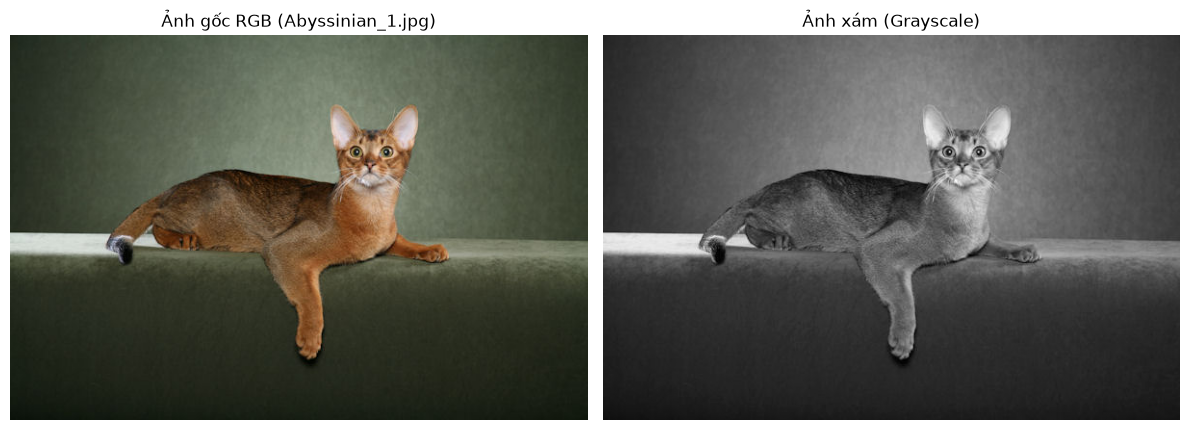

In [2]:
# Chọn ảnh mẫu đầu tiên
sample_img_name = all_jpg_files[0]
img_path = os.path.join(dataset_images_dir, sample_img_name)

# Đọc ảnh bằng OpenCV (mặc định BGR) và chuyển sang RGB để hiển thị đúng bằng Matplotlib
img_bgr = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

print(f"Đang phân tích ảnh: {sample_img_name}")
print(f"Kích thước ảnh: {img_rgb.shape} (Cao x Rộng x Kênh màu)")

# Hiển thị ảnh gốc và ảnh xám
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_rgb)
axes[0].set_title(f"Ảnh gốc RGB ({sample_img_name})")
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title("Ảnh xám (Grayscale)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 3. Vẽ và Phân tích Histogram Ảnh Xám (Grayscale Histogram)

Chúng ta sẽ vẽ histogram của ảnh xám mẫu bằng cách sử dụng `cv2.calcHist()` của OpenCV (tính toán tần số trước rồi vẽ bằng `plt.plot()`).

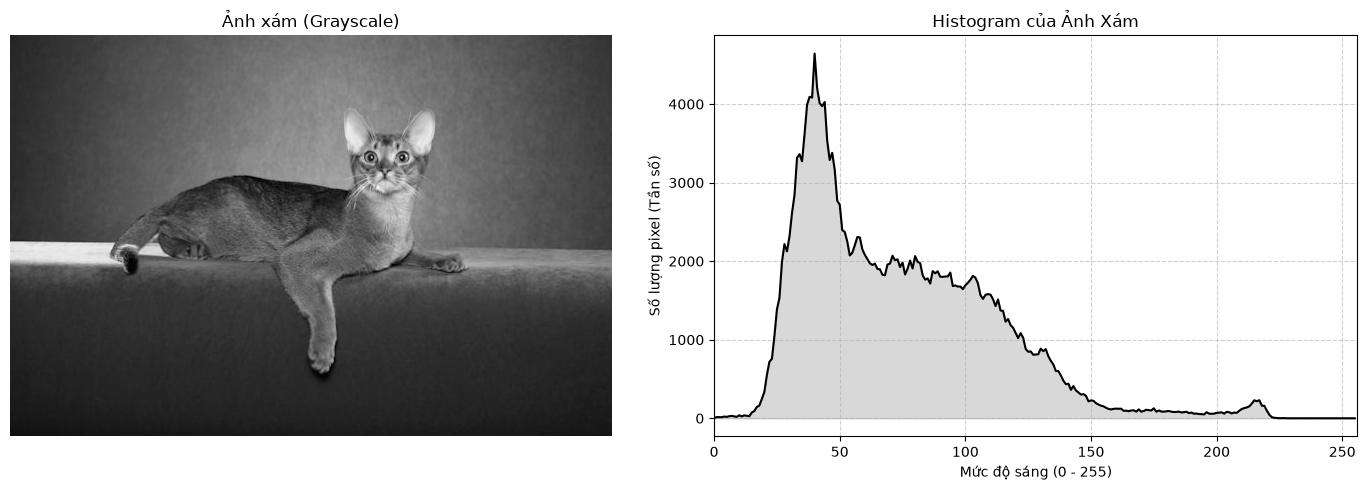

In [3]:
hist_cv = cv2.calcHist([img_gray], [0], None, [256], [0, 256]).flatten()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Trực quan hóa ảnh xám
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title("Ảnh xám (Grayscale)")
axes[0].axis('off')

# Vẽ Histogram xám
axes[1].plot(hist_cv, color='black', linewidth=1.5)
axes[1].fill_between(range(256), hist_cv, color='gray', alpha=0.3)
axes[1].set_title("Histogram của Ảnh Xám")
axes[1].set_xlabel("Mức độ sáng (0 - 255)")
axes[1].set_ylabel("Số lượng pixel (Tần số)")
axes[1].set_xlim([0, 256])
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Nhận xét & Đánh giá Histogram Ảnh Xám:
1.  **Dải động (Dynamic Range):** Quan sát trục X, xem các pixel phân bố trong khoảng nào. Nếu trải dài từ gần 0 đến gần 255, ảnh có dải động tốt, chi tiết tối và sáng đều rõ ràng.
2.  **Độ tương phản (Contrast):** Xem độ rộng của đỉnh đồ thị. Nếu biểu đồ tập trung hẹp lại thành một khối nhỏ ở giữa, ảnh có độ tương phản thấp. Nếu trải rộng và đều, độ tương phản cao.
3.  **Hình dáng biểu đồ (Histogram Shape):** Biểu đồ có thể có một đỉnh duy nhất (unimodal) hoặc nhiều đỉnh (multimodal). Thường một đỉnh đại diện cho vùng nền (background) và đỉnh còn lại đại diện cho chủ thể vật thể (con vật/mèo/chó) nếu độ sáng của chúng khác nhau rõ rệt.

## 4. Vẽ và Phân tích Histogram Ảnh Màu (RGB Color Histograms)

Ảnh màu gồm 3 kênh R, G, B xếp chồng. Chúng ta sẽ tính toán histogram cho từng kênh và vẽ chúng với các màu tương ứng (Đỏ, Xanh lá, Xanh dương).

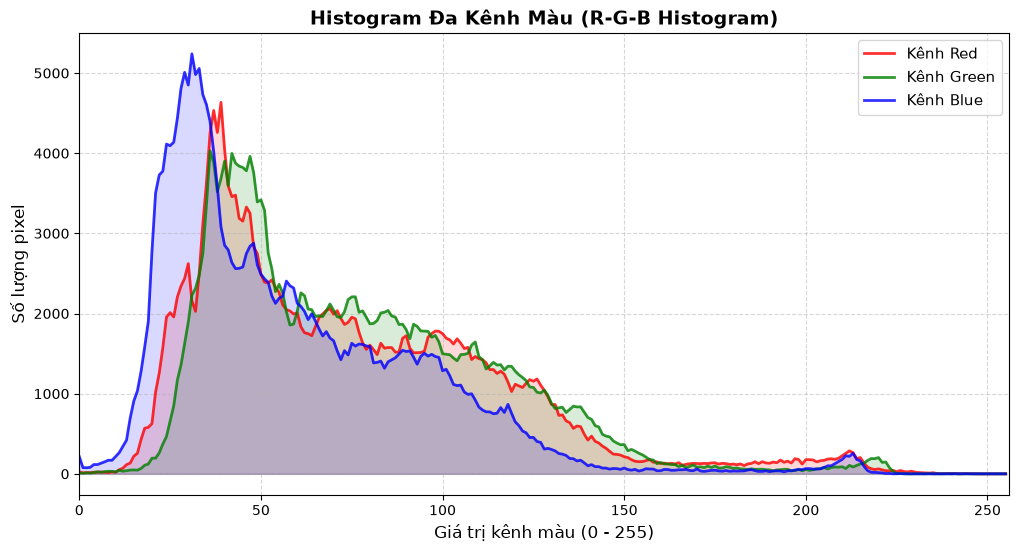

In [4]:
colors = ('red', 'green', 'blue')
channel_names = ('Kênh Red', 'Kênh Green', 'Kênh Blue')

plt.figure(figsize=(12, 6))

# Tính và vẽ histogram cho mỗi kênh màu
for i, col in enumerate(colors):
    hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256]).flatten()
    plt.plot(hist, color=col, label=channel_names[i], linewidth=2.0, alpha=0.8)
    plt.fill_between(range(256), hist, color=col, alpha=0.15)

plt.title("Histogram Đa Kênh Màu (R-G-B Histogram)", fontsize=14, fontweight='bold')
plt.xlabel("Giá trị kênh màu (0 - 255)", fontsize=12)
plt.ylabel("Số lượng pixel", fontsize=12)
plt.xlim([0, 256])
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Nhận xét & Đánh giá Histogram Màu:
1.  **Sự tương quan giữa các kênh màu (Color Balance):**
    *   Nếu cả 3 đường màu trùng khớp nhau hoặc có hình dáng rất giống nhau, bức ảnh có xu hướng thiên về tông màu trung tính (grayscale/trắng đen/xám).
    *   Nếu có một đường lệch hẳn hoặc có đỉnh rất lớn vượt trội so với các đường còn lại, màu đó là màu chủ đạo (dominant color) trong bức ảnh.
2.  **Đặc tính màu sắc của ảnh hiện tại:**
    *   *Ví dụ:* Nếu đường màu đỏ lệch nhiều về phía bên phải (giá trị cao) so với màu xanh dương, ảnh có tông màu ấm áp (warm tone, nhiều đỏ/cam/vàng).
    *   Nếu kênh xanh lá (Green) và xanh dương (Blue) chiếm ưu thế ở dải sáng cao, ảnh mang tông màu lạnh (cool tone) hoặc có nhiều cây cối, bầu trời.

## 5. Trực quan hóa sự thay đổi Histogram theo Độ Sáng và Độ Tương Phản

Để hiểu rõ hơn nguyên lý hoạt động của histogram, chúng ta sẽ lập trình biến đổi độ sáng và độ tương phản của ảnh gốc và quan sát sự biến chuyển của biểu đồ.

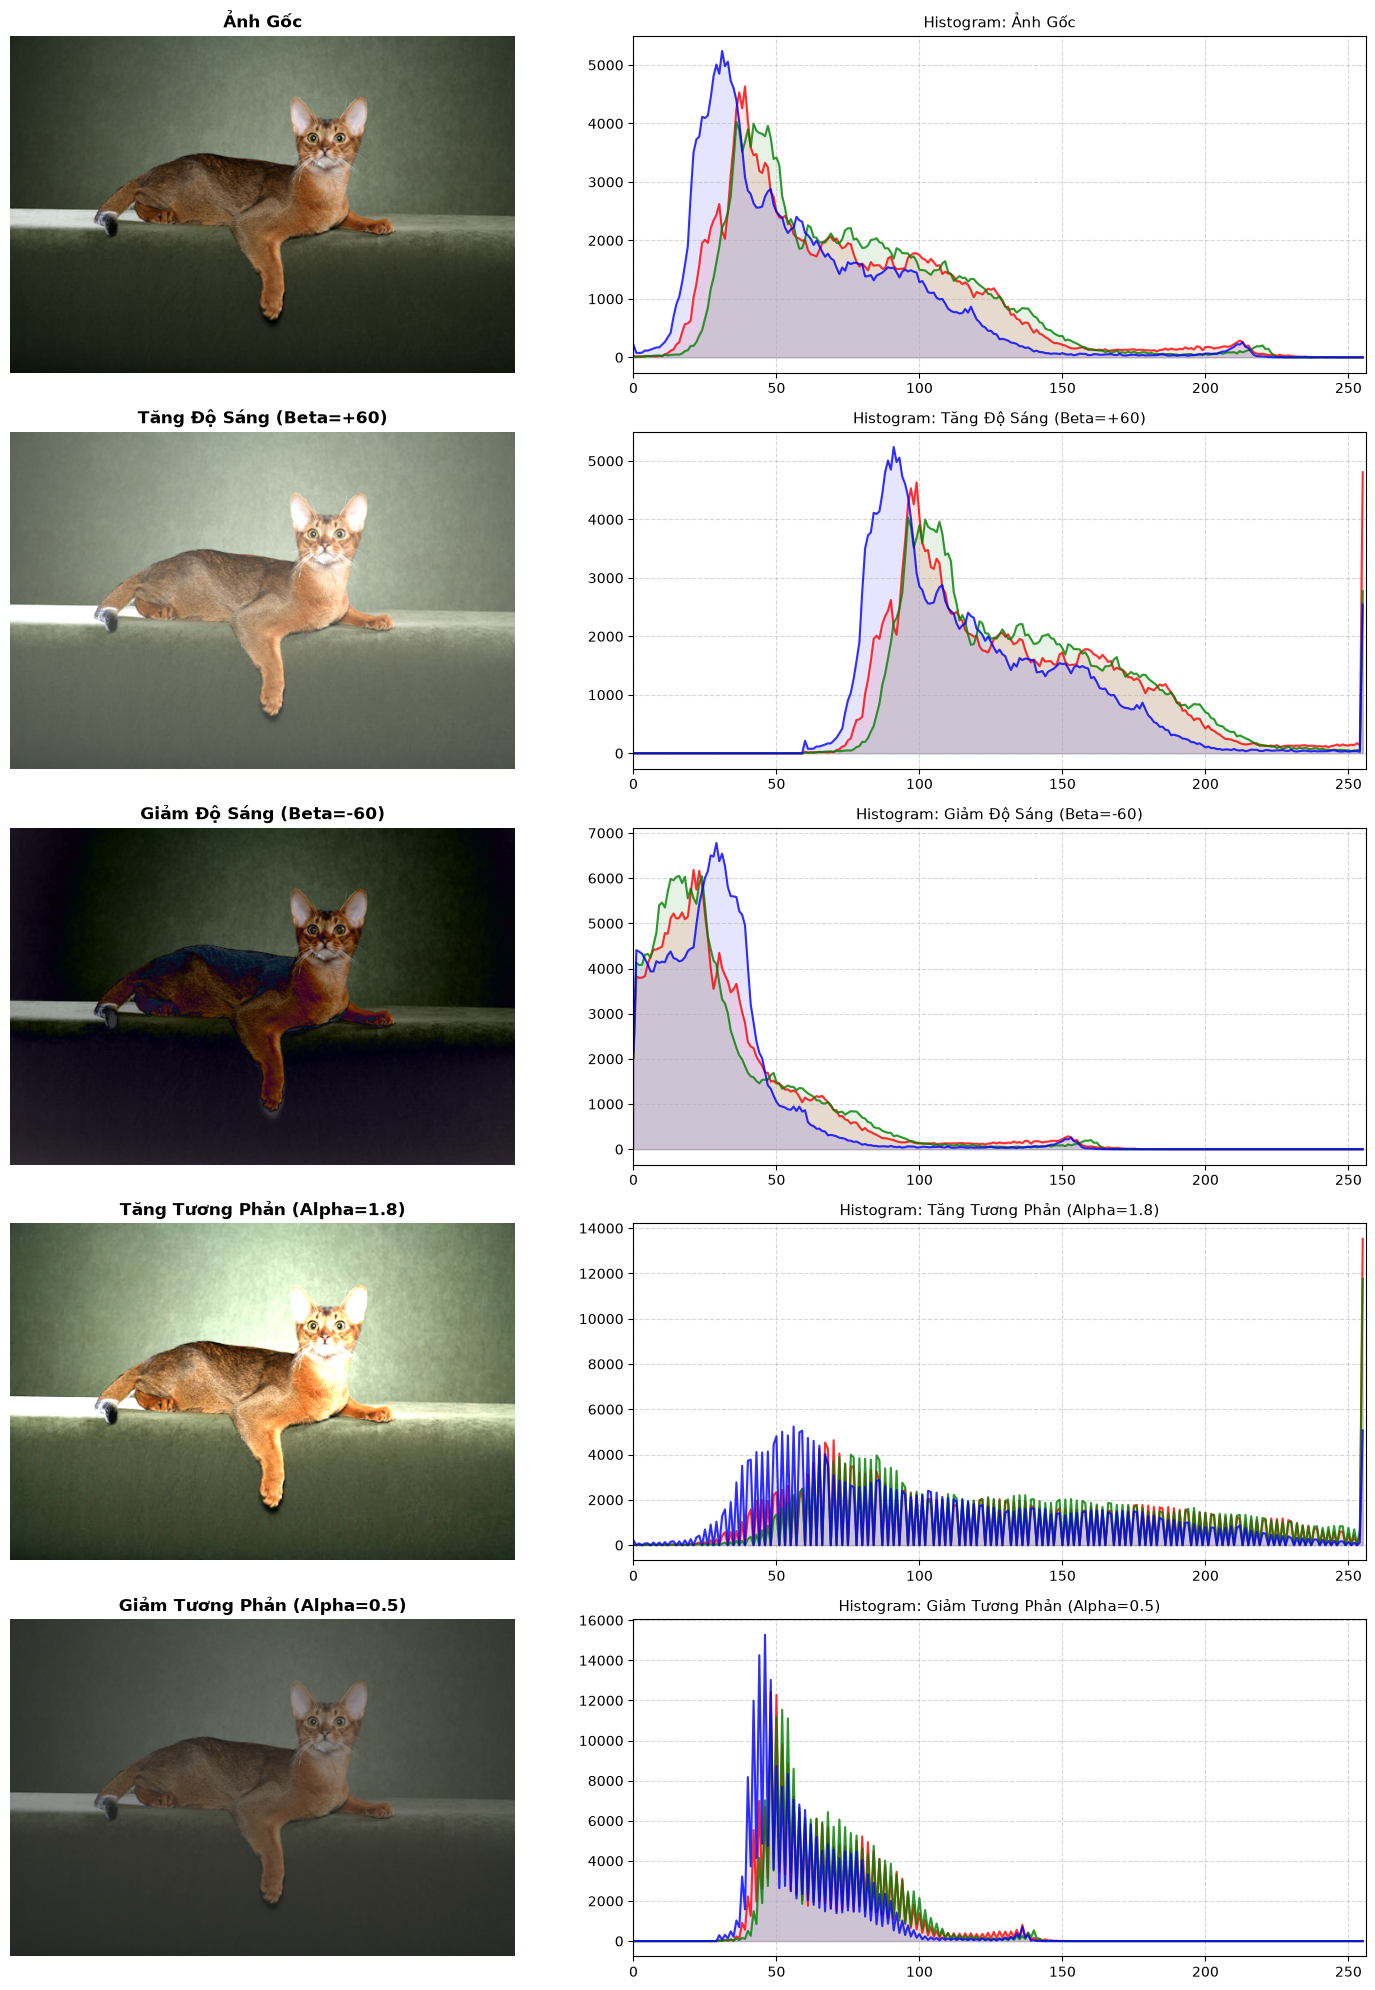

In [5]:
# Hàm biến đổi độ sáng và tương phản
# g(x) = alpha * f(x) + beta
def adjust_brightness_contrast(image, alpha=1.0, beta=0):
    new_img = cv2.convertScaleAbs(image, alpha=alpha, beta=beta)
    return new_img

# Tạo 4 phiên bản ảnh khác nhau
img_bright = adjust_brightness_contrast(img_rgb, alpha=1.0, beta=60)     # Tăng độ sáng
img_dark = adjust_brightness_contrast(img_rgb, alpha=1.0, beta=-60)      # Giảm độ sáng
img_high_con = adjust_brightness_contrast(img_rgb, alpha=1.8, beta=0)    # Tăng tương phản
img_low_con = adjust_brightness_contrast(img_rgb, alpha=0.5, beta=30)    # Giảm tương phản

modifications = [
    ("Ảnh Gốc", img_rgb),
    ("Tăng Độ Sáng (Beta=+60)", img_bright),
    ("Giảm Độ Sáng (Beta=-60)", img_dark),
    ("Tăng Tương Phản (Alpha=1.8)", img_high_con),
    ("Giảm Tương Phản (Alpha=0.5)", img_low_con)
]

# Vẽ lưới 5 hàng x 2 cột (Ảnh bên trái, Histogram RGB bên phải)
fig, axes = plt.subplots(5, 2, figsize=(15, 20))

for idx, (title, img_mod) in enumerate(modifications):
    # 1. Hiển thị ảnh
    axes[idx, 0].imshow(img_mod)
    axes[idx, 0].set_title(title, fontsize=12, fontweight='bold')
    axes[idx, 0].axis('off')
    
    # 2. Vẽ histogram màu RGB
    for i, col in enumerate(colors):
        hist = cv2.calcHist([img_mod], [i], None, [256], [0, 256]).flatten()
        axes[idx, 1].plot(hist, color=col, linewidth=1.5, alpha=0.8)
        axes[idx, 1].fill_between(range(256), hist, color=col, alpha=0.1)
    
    axes[idx, 1].set_title(f"Histogram: {title}", fontsize=11)
    axes[idx, 1].set_xlim([0, 256])
    axes[idx, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Nhận xét chi tiết về sự thay đổi của Histogram:

1.  **Khi tăng độ sáng (Beta = +60):**
    *   **Ảnh:** Toàn bộ bức ảnh sáng lên rõ rệt, một số vùng sáng có thể bị lóa trắng.
    *   **Histogram:** Toàn bộ biểu đồ dịch chuyển tịnh tiến sang **bên phải (hướng tới giá trị 255)**.
2.  **Khi giảm độ sáng (Beta = -60):**
    *   **Ảnh:** Bức ảnh trở nên tối tăm, nhiều chi tiết trong bóng tối bị mất đi.
    *   **Histogram:** Toàn bộ biểu đồ dịch chuyển tịnh tiến sang **bên trái (hướng tới giá trị 0)**.
3.  **Khi tăng độ tương phản (Alpha = 1.8):**
    *   **Ảnh:** Vùng sáng trở nên sáng hơn nữa, vùng tối trở nên tối hơn nữa.
    *   **Histogram:** Biểu đồ bị **kéo dãn ra hai phía đầu mút (0 và 255)**. Tạo các đỉnh lớn ở rìa trái và rìa phải.
4.  **Khi giảm độ tương phản (Alpha = 0.5):**
    *   **Ảnh:** Ảnh có cảm giác bị phủ một lớp sương mù màu xám, mất đi sự phân biệt rõ ràng giữa các mảng sáng tối.
    *   **Histogram:** Biểu đồ bị **nén co cụm lại ở giữa**.

## 6. Tổng Hợp Histogram Của Toàn Bộ Tập Dữ Liệu (Aggregate Dataset Histogram)

In [6]:
# Khởi tạo mảng tích lũy histogram toàn cục cho ảnh xám và các kênh RGB làm mảng 1D (256 phần tử)
total_gray_hist = np.zeros(256, dtype=np.float64)
total_r_hist = np.zeros(256, dtype=np.float64)
total_g_hist = np.zeros(256, dtype=np.float64)
total_b_hist = np.zeros(256, dtype=np.float64)

print("Bắt đầu xử lý toàn bộ dataset để tính toán histogram tổng hợp...")

# Duyệt qua tất cả các ảnh trong dataset (hiển thị tiến trình bằng tqdm)
valid_image_count = 0
for filename in tqdm(all_jpg_files, desc="Đang xử lý ảnh"):
    img_path = os.path.join(dataset_images_dir, filename)
    # Đọc ảnh gốc bằng OpenCV
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        continue
        
    # 1. Tính toán cho ảnh xám
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray_hist = cv2.calcHist([img_gray], [0], None, [256], [0, 256]).flatten()
    total_gray_hist += gray_hist
    
    # 2. Tính toán cho ảnh màu RGB (lưu ý OpenCV đọc dạng BGR nên chỉ số tương ứng là 2, 1, 0)
    r_hist = cv2.calcHist([img_bgr], [2], None, [256], [0, 256]).flatten()
    g_hist = cv2.calcHist([img_bgr], [1], None, [256], [0, 256]).flatten()
    b_hist = cv2.calcHist([img_bgr], [0], None, [256], [0, 256]).flatten()
    
    total_r_hist += r_hist
    total_g_hist += g_hist
    total_b_hist += b_hist
    
    valid_image_count += 1

print(f"Thành công! Đã tổng hợp dữ liệu từ {valid_image_count} ảnh.")

Bắt đầu xử lý toàn bộ dataset để tính toán histogram tổng hợp...


Đang xử lý ảnh: 100%|██████████| 7390/7390 [00:11<00:00, 660.64it/s]

Thành công! Đã tổng hợp dữ liệu từ 7390 ảnh.


Bây giờ, chúng ta sẽ chuẩn hóa (chia cho tổng số ảnh để lấy trung bình) và vẽ các biểu đồ histogram toàn cục của dataset.

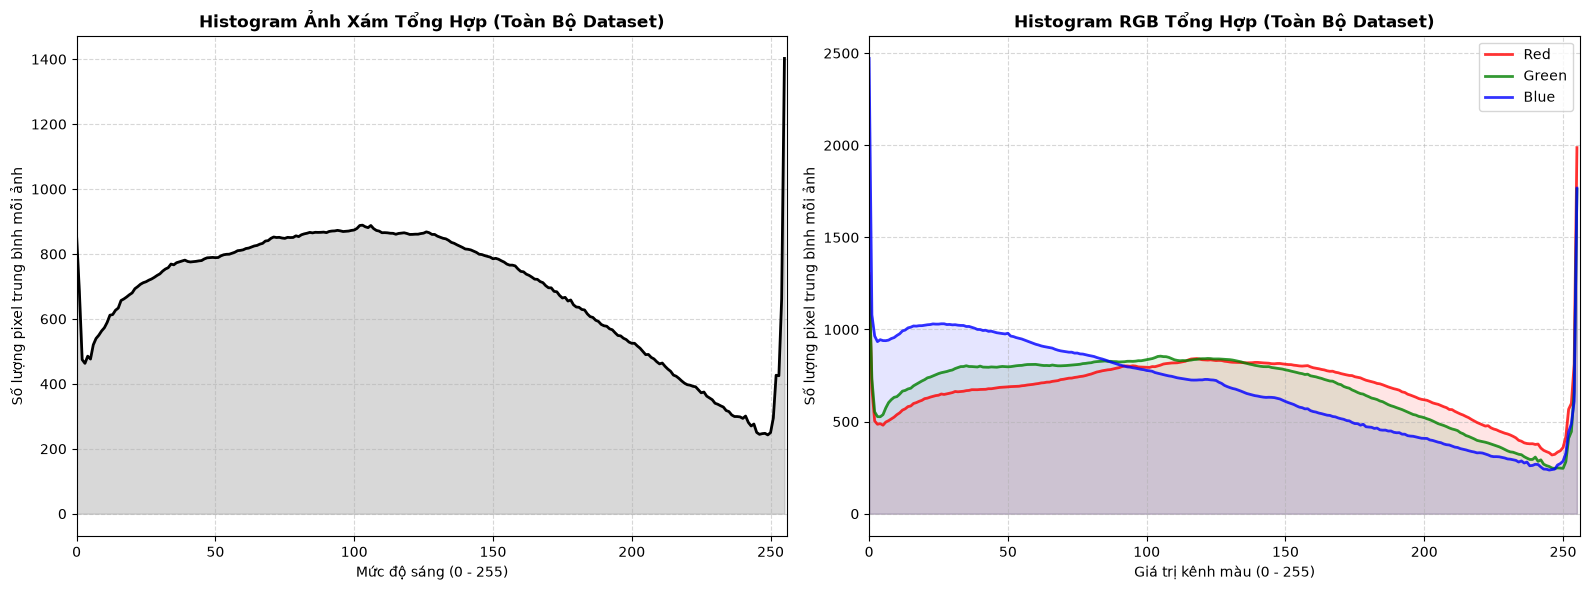

In [7]:
# Chia lấy trung bình để histogram phản ánh phân phối chuẩn của 1 ảnh đại diện trong dataset
avg_gray_hist = total_gray_hist / valid_image_count
avg_r_hist = total_r_hist / valid_image_count
avg_g_hist = total_g_hist / valid_image_count
avg_b_hist = total_b_hist / valid_image_count

# Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Vẽ Histogram Ảnh Xám Tổng Hợp
axes[0].plot(avg_gray_hist, color='black', linewidth=2.0)
axes[0].fill_between(range(256), avg_gray_hist, color='gray', alpha=0.3)
axes[0].set_title("Histogram Ảnh Xám Tổng Hợp (Toàn Bộ Dataset)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Mức độ sáng (0 - 255)")
axes[0].set_ylabel("Số lượng pixel trung bình mỗi ảnh")
axes[0].set_xlim([0, 256])
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Vẽ Histogram RGB Tổng Hợp
axes[1].plot(avg_r_hist, color='red', label='Red', linewidth=2.0, alpha=0.8)
axes[1].fill_between(range(256), avg_r_hist, color='red', alpha=0.1)
axes[1].plot(avg_g_hist, color='green', label='Green', linewidth=2.0, alpha=0.8)
axes[1].fill_between(range(256), avg_g_hist, color='green', alpha=0.1)
axes[1].plot(avg_b_hist, color='blue', label='Blue', linewidth=2.0, alpha=0.8)
axes[1].fill_between(range(256), avg_b_hist, color='blue', alpha=0.1)
axes[1].set_title("Histogram RGB Tổng Hợp (Toàn Bộ Dataset)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Giá trị kênh màu (0 - 255)")
axes[1].set_ylabel("Số lượng pixel trung bình mỗi ảnh")
axes[1].set_xlim([0, 256])
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Nhận xét & Đánh giá Tổng Quan Toàn Bộ Tập Dữ Liệu Oxford-IIIT Pet:

1.  **Tính phân bố ánh sáng (Grayscale Distribution):**
    *   Biểu đồ histogram xám tổng hợp cho thấy một hình dáng trải rộng, hơi nghiêng về dải sáng trung bình đến cao (khoảng từ 50 đến 220), có một đỉnh nhẹ ở các vùng trung tính.
    *   Điều này chỉ ra rằng tập dữ liệu **Oxford-IIIT Pet** được chụp trong môi trường ánh sáng đầy đủ (outdoor/indoor ban ngày chiếm đa số), ảnh rất ít khi bị tối đen hoàn toàn hoặc lóa trắng xóa hoàn toàn. Dải động rất cân đối và phù hợp cho việc huấn luyện mô hình.
2.  **Đặc tính màu sắc toàn cục (Global Color Distribution):**
    *   Quan sát biểu đồ RGB tổng hợp, ba kênh màu Đỏ (Red), Xanh lá (Green), và Xanh dương (Blue) phân bố tương đối cân bằng và bám khá sát nhau ở phần lớn dải sáng.
    *   Tuy nhiên, kênh **Red** và kênh **Green** có xu hướng nhỉnh hơn kênh **Blue** một chút ở dải giá trị từ 80 đến 180. Điều này giải thích là do các bức ảnh chụp thú cưng (chó, mèo) thường có màu lông thuộc tông ấm (vàng, nâu, cam, trắng sữa) kết hợp với hậu cảnh cỏ cây xanh lá (Green). Kênh Blue thấp hơn do ít có nền trời xanh dương xuất hiện cận cảnh.

---

## 7. Tổng kết và Ý nghĩa đối với bài toán phân loại ảnh với CLIP

*   **Đặc trưng màu sắc và cấu trúc:** Histogram tóm tắt phân phối màu toàn cục nhưng **không giữ thông tin không gian (spatial info)**. Ví dụ, hai bức ảnh có cùng số lượng điểm ảnh đỏ và xanh nhưng sắp xếp khác nhau (một ảnh là con mèo đỏ trên nền cỏ xanh, một ảnh là vòng tròn đỏ giữa thảm cỏ xanh) sẽ có histogram giống hệt nhau.
*   **Hạn chế của mô hình truyền thống:** Các phương pháp thị giác máy tính cổ điển thường trích xuất đặc trưng histogram màu làm đặc trưng chính (Global Color Feature) nên dễ bị nhầm lẫn bởi các thay đổi về bố cục không gian.
*   **Sự vượt trội của học sâu & CLIP:** Mô hình CLIP (Contrastive Language-Image Pretraining) sử dụng kiến trúc mạng Transformer hoặc CNN sâu để học các đặc trưng ngữ nghĩa phức tạp (chủ thể, hành động, chất liệu, bối cảnh không gian) thay vì chỉ dựa vào phân phối pixel đơn lẻ như histogram. Tuy nhiên, việc hiểu histogram giúp chúng ta tiền xử lý ảnh tốt hơn (như chuẩn hóa độ sáng, tăng cường dữ liệu) nhằm nâng cao độ chính xác của CLIP.